# Phase 2 — Dataset Acquisition, Inspection, and Validation
**Project:** Explainable and Generalization-Aware Phishing URL Detection Using Machine Learning and SHAP

This notebook performs a rigorous, empirical inspection of our two research datasets:
1. **LegitPhish (Primary Dataset):** Acquired from Mendeley Data (DOI: 10.17632/hx4m73v2sf.2).
2. **PhiUSIIL (External Validation Dataset):** Acquired from UCI Machine Learning Repository (DOI: 10.1016/j.cose.2023.103545).

**Strict Research Constraint:**
Our detection system evaluates phishing risk exclusively from URL strings. Webpage-derived features, HTML source code, DNS/WHOIS lookups, and network responses are excluded. All analysis in this notebook is performed strictly offline without querying or visiting any URL.


In [1]:
import sys
from pathlib import Path

# Add project root to path robustly
cwd = Path.cwd().resolve()
if (cwd / "src").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "src").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data.load_data import (
    load_legitphish,
    load_phiusiil,
    LEGITPHISH_CSV,
    PHIUSIIL_CSV,
    LEGITPHISH_EXPECTED_SHA256,
    PHIUSIIL_CSV_EXPECTED_SHA256,
    compute_file_sha256,
    verify_dataset_integrity
)
from src.data.preprocess import (
    parse_url_components,
    extract_registrable_domain,
    identify_duplicate_urls,
    identify_conflicting_label_urls,
    identify_conflicting_label_domains
)
from src.data.dataset_audit import (
    audit_single_dataset,
    audit_cross_dataset
)

pd.set_option("display.max_columns", 25)
print("Environment and modules successfully initialized.")


Environment and modules successfully initialized.


## 1. LegitPhish Dataset Acquisition & Integrity
We verify the integrity of the downloaded raw file against its official Mendeley Data SHA-256 cryptographic digest.


In [2]:
legit_valid, legit_sha = verify_dataset_integrity(LEGITPHISH_CSV, LEGITPHISH_EXPECTED_SHA256)
print(f"File Path: {LEGITPHISH_CSV}")
print(f"File Size: {LEGITPHISH_CSV.stat().st_size:,} bytes ({LEGITPHISH_CSV.stat().st_size / (1024*1024):.2f} MB)")
print(f"SHA-256:   {legit_sha}")
print(f"Official Checksum Match: {legit_valid}")


File Path: /Users/pratyushsharma/Desktop/phishing-detection-research/data/raw/legitphish/url_features_extracted1.csv
File Size: 8,963,838 bytes (8.55 MB)
SHA-256:   8685e7901c3b4e73eb43c106cb166cc932dd14f76960a032c713c2c32f09dbcd
Official Checksum Match: True


In [3]:
df_legit = load_legitphish(url_only=False)
print(f"LegitPhish Dimensions: {df_legit.shape[0]:,} rows x {df_legit.shape[1]} columns")
print("\nColumn list:")
for i, col in enumerate(df_legit.columns):
    print(f"  {i+1:2d}. {col:25s} ({df_legit[col].dtype})")


LegitPhish Dimensions: 101,219 rows x 18 columns

Column list:
   1. URL                       (str)
   2. url_length                (int64)
   3. has_ip_address            (int64)
   4. dot_count                 (int64)
   5. https_flag                (int64)
   6. url_entropy               (float64)
   7. token_count               (int64)
   8. subdomain_count           (int64)
   9. query_param_count         (int64)
  10. tld_length                (int64)
  11. path_length               (int64)
  12. has_hyphen_in_domain      (int64)
  13. number_of_digits          (int64)
  14. tld_popularity            (int64)
  15. suspicious_file_extension (int64)
  16. domain_name_length        (int64)
  17. percentage_numeric_chars  (float64)
  18. ClassLabel                (float64)


### Missing Value Inspection
We inspect all columns in LegitPhish for null or unpopulated entries.


In [4]:
missing_legit = df_legit.isnull().sum()
cols_with_na = missing_legit[missing_legit > 0]
print("Columns with missing values in LegitPhish:")
print(cols_with_na)

# Highlight the exact row with missing ClassLabel
na_row = df_legit[df_legit["ClassLabel"].isnull()]
print(f"\nRow index with missing ClassLabel: {na_row.index.tolist()}")
display(na_row[["URL", "ClassLabel", "url_length", "dot_count", "https_flag"]])


Columns with missing values in LegitPhish:
ClassLabel    1
dtype: int64

Row index with missing ClassLabel: [65118]
                                  URL  ClassLabel  url_length  dot_count  https_flag
65118  https://www.chocolatleroux.com         NaN          30          2           1


### Label Distribution & Data Quality
LegitPhish defines `ClassLabel`:
- `0`: Phishing URL
- `1`: Legitimate URL


In [5]:
counts_l = df_legit["ClassLabel"].value_counts(dropna=False)
pcts_l = df_legit["ClassLabel"].value_counts(normalize=True, dropna=False) * 100

summary_l = pd.DataFrame({
    "Count": counts_l,
    "Percentage (%)": pcts_l.round(2)
})
print("LegitPhish Class Distribution:")
display(summary_l)

exact_dups_l = df_legit.duplicated().sum()
dup_urls_l = df_legit["URL"].duplicated().sum()
conflicting_urls_l = identify_conflicting_label_urls(df_legit, url_col="URL", label_col="ClassLabel")

print(f"Exact Duplicate Rows:       {exact_dups_l:,}")
print(f"Duplicate URL Strings:      {dup_urls_l:,}")
print(f"Conflicting-Label URLs:     {len(conflicting_urls_l):,}")


LegitPhish Class Distribution:
            Count  Percentage (%)
ClassLabel                       
0.0         63678           62.91
1.0         37540           37.09
NaN             1            0.00
Exact Duplicate Rows:       346
Duplicate URL Strings:      346
Conflicting-Label URLs:     0


## 2. PhiUSIIL Dataset Acquisition & Integrity
PhiUSIIL is our external validation dataset acquired from the UCI Machine Learning Repository.


In [6]:
phi_valid, phi_sha = verify_dataset_integrity(PHIUSIIL_CSV, PHIUSIIL_CSV_EXPECTED_SHA256)
print(f"File Path: {PHIUSIIL_CSV}")
print(f"File Size: {PHIUSIIL_CSV.stat().st_size:,} bytes ({PHIUSIIL_CSV.stat().st_size / (1024*1024):.2f} MB)")
print(f"SHA-256:   {phi_sha}")
print(f"Official Checksum Match: {phi_valid}")


File Path: /Users/pratyushsharma/Desktop/phishing-detection-research/data/raw/phiusil/PhiUSIIL_Phishing_URL_Dataset.csv
File Size: 56,854,345 bytes (54.22 MB)
SHA-256:   a236549cd369cd80bd478ff8e1779cbf44c58d5c3f79f7a51a1adbed7d06d1c6
Official Checksum Match: True


In [7]:
df_phi_full = load_phiusiil(url_only=False)
print(f"PhiUSIIL Dimensions: {df_phi_full.shape[0]:,} rows x {df_phi_full.shape[1]} columns")
print(f"Missing Values Across Entire Dataset: {df_phi_full.isnull().sum().sum()}")


PhiUSIIL Dimensions: 235,795 rows x 56 columns
Missing Values Across Entire Dataset: 0


### Strict URL-Only Research Isolation
In accordance with our research protocol, all 54 webpage-derived features (HTML content, DOM elements, title matches, external scripts) are discarded. We isolate strictly `URL` and `label`.


In [8]:
df_phi = load_phiusiil(url_only=True)
print(f"Isolated URL-Only Schema: {df_phi.columns.tolist()}")

counts_p = df_phi["label"].value_counts(dropna=False)
pcts_p = df_phi["label"].value_counts(normalize=True, dropna=False) * 100

summary_p = pd.DataFrame({
    "Count": counts_p,
    "Percentage (%)": pcts_p.round(2)
})
print("PhiUSIIL Class Distribution (0=Phishing, 1=Legitimate):")
display(summary_p)

exact_dups_p = df_phi_full.duplicated().sum()
dup_urls_p = df_phi["URL"].duplicated().sum()
conflicting_urls_p = identify_conflicting_label_urls(df_phi, url_col="URL", label_col="label")

print(f"Exact Duplicate Rows:       {exact_dups_p:,}")
print(f"Duplicate URL Strings:      {dup_urls_p:,}")
print(f"Conflicting-Label URLs:     {len(conflicting_urls_p):,}")


Isolated URL-Only Schema: ['URL', 'label']
PhiUSIIL Class Distribution (0=Phishing, 1=Legitimate):
        Count  Percentage (%)
label                        
1      134850           57.19
0      100945           42.81
Exact Duplicate Rows:       0
Duplicate URL Strings:      425
Conflicting-Label URLs:     0


## 3. Offline Domain-Level Analysis & Data Leakage Assessment
We parse URLs strictly offline to extract registrable domains (eTLD+1) and evaluate:
- Domain repetition within each dataset
- Conflicting-label domains (domains hosting both phishing and legitimate content)
- Cross-dataset domain and URL overlap


In [9]:
# Extract domains for LegitPhish
doms_legit = df_legit["URL"].dropna().apply(extract_registrable_domain)
doms_legit_clean = doms_legit[doms_legit != ""]

# Extract domains for PhiUSIIL
doms_phi = df_phi["URL"].dropna().apply(extract_registrable_domain)
doms_phi_clean = doms_phi[doms_phi != ""]

print(f"LegitPhish Unique Registrable Domains: {doms_legit_clean.nunique():,}")
print(f"PhiUSIIL Unique Registrable Domains:   {doms_phi_clean.nunique():,}")

# Top repeated domains in PhiUSIIL
print("\nTop 5 Repeated Domains in PhiUSIIL (Shared Hosting/Cloud Services):")
print(doms_phi_clean.value_counts().head(5))

# Conflicting domains in each dataset
conf_doms_l = identify_conflicting_label_domains(
    pd.DataFrame({"registrable_domain": doms_legit, "label": df_legit["ClassLabel"]}),
    domain_col="registrable_domain", label_col="label"
)
conf_doms_p = identify_conflicting_label_domains(
    pd.DataFrame({"registrable_domain": doms_phi, "label": df_phi["label"]}),
    domain_col="registrable_domain", label_col="label"
)

print(f"\nConflicting-Label Domains in LegitPhish: {len(conf_doms_l)}")
print(f"Conflicting-Label Domains in PhiUSIIL:   {len(conf_doms_p)}")


LegitPhish Unique Registrable Domains: 62,152
PhiUSIIL Unique Registrable Domains:   172,296

Top 5 Repeated Domains in PhiUSIIL (Shared Hosting/Cloud Services):
URL
web.app            5754
firebaseapp.com    5594
repl.co            3754
weeblysite.com     3097
ipfs.io            1559
Name: count, dtype: int64

Conflicting-Label Domains in LegitPhish: 30
Conflicting-Label Domains in PhiUSIIL:   223


## 4. Cross-Dataset Leakage and Generalization Implications
We compute the intersection of exact URLs and registrable domains between LegitPhish and PhiUSIIL.


In [10]:
urls_l_set = set(df_legit["URL"].dropna().astype(str).str.strip().unique())
urls_p_set = set(df_phi["URL"].dropna().astype(str).str.strip().unique())
exact_url_overlap = urls_l_set.intersection(urls_p_set)

doms_l_set = set(doms_legit_clean.unique())
doms_p_set = set(doms_phi_clean.unique())
domain_overlap = doms_l_set.intersection(doms_p_set)

print(f"Exact URL Overlap: {len(exact_url_overlap):,} URLs")
print(f"Registrable Domain Overlap: {len(domain_overlap):,} domains")
print(f"Overlap as % of LegitPhish Domains: {(len(domain_overlap) / len(doms_l_set)) * 100:.2f}%")
print(f"Overlap as % of PhiUSIIL Domains:   {(len(domain_overlap) / len(doms_p_set)) * 100:.2f}%")

# Inspect class distribution of overlapping URLs
merged_urls = df_legit.merge(df_phi, on="URL", suffixes=("_legitphish", "_phiusiil"))
print("\nClass Distribution of the Overlapping URLs:")
print(merged_urls["label"].value_counts())


Exact URL Overlap: 36,936 URLs
Registrable Domain Overlap: 35,925 domains
Overlap as % of LegitPhish Domains: 57.80%
Overlap as % of PhiUSIIL Domains:   20.85%

Class Distribution of the Overlapping URLs:
label
1    36936
Name: count, dtype: int64


## 5. Visual Summary of Class Distributions and Overlap

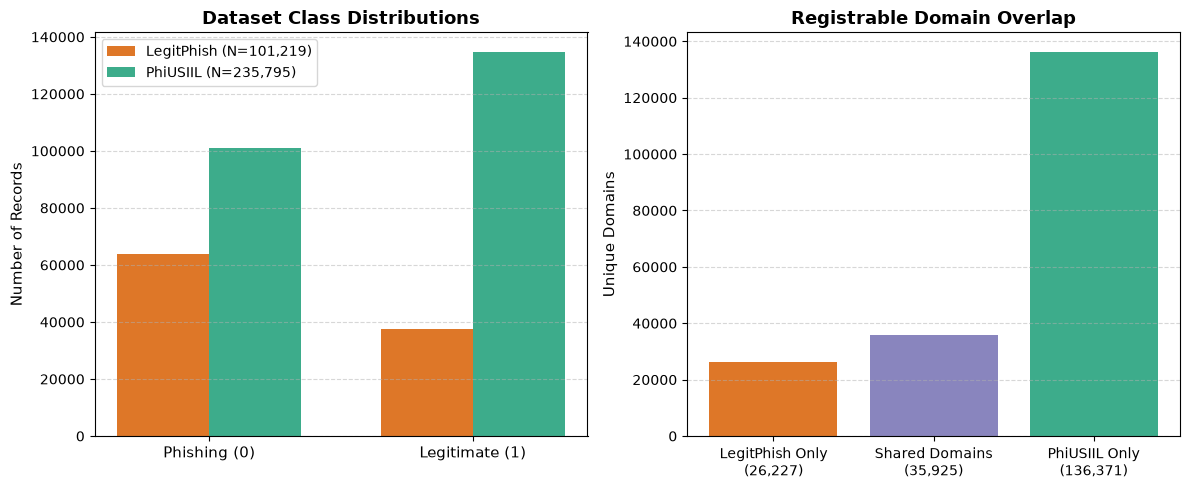

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Class Distributions
labels = ["Phishing (0)", "Legitimate (1)"]
legit_counts = [df_legit["ClassLabel"].value_counts().get(0.0, 0), df_legit["ClassLabel"].value_counts().get(1.0, 0)]
phi_counts = [df_phi["label"].value_counts().get(0, 0), df_phi["label"].value_counts().get(1, 0)]

x = np.arange(len(labels))
width = 0.35

axes[0].bar(x - width/2, legit_counts, width, label="LegitPhish (N=101,219)", color="#d95f02", alpha=0.85)
axes[0].bar(x + width/2, phi_counts, width, label="PhiUSIIL (N=235,795)", color="#1b9e77", alpha=0.85)
axes[0].set_title("Dataset Class Distributions", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Number of Records", fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, fontsize=11)
axes[0].legend(fontsize=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Subplot 2: Domain Overlap Breakdown
domain_metrics = [
    len(doms_l_set) - len(domain_overlap),
    len(domain_overlap),
    len(doms_p_set) - len(domain_overlap)
]
domain_labels = [
    f"LegitPhish Only\n({domain_metrics[0]:,})",
    f"Shared Domains\n({domain_metrics[1]:,})",
    f"PhiUSIIL Only\n({domain_metrics[2]:,})"
]
axes[1].bar(domain_labels, domain_metrics, color=["#d95f02", "#7570b3", "#1b9e77"], alpha=0.85)
axes[1].set_title("Registrable Domain Overlap", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Unique Domains", fontsize=11)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 6. Key Research Audit Takeaways
1. **Verified Authenticity:** Both LegitPhish and PhiUSIIL have been verified bit-for-bit against their official repository SHA-256 hashes.
2. **Missing Label in LegitPhish:** Row `65118` (`https://www.chocolatleroux.com`) has a `NaN` label and must be dropped during preprocessing.
3. **Severe Cross-Dataset Leakage Risk:** 36,936 URLs (98.39% of all legitimate URLs in LegitPhish) are identical to URLs in PhiUSIIL, all labeled legitimate. 35,925 registrable domains (57.80% of LegitPhish domains) overlap with PhiUSIIL.
4. **Methodological Requirement:** Naive external validation on PhiUSIIL will produce artificially inflated accuracy due to memorized legitimate domains. The evaluation protocol in `methodology.md` MUST implement strict domain-aware filtering and deduplication before testing external generalization.
